### Este notebook foi utilizado para gerar os parquets limpos (apenas com possession_id). Não é necessário executá-lo novamente

# Processamento em Lote de Dados de Tracking

Este notebook aplica um processo de limpeza e filtragem em múltiplos arquivos de tracking e seus respectivos metadados. A rotina faz o seguinte para cada jogo:

1.  **Lê os metadados** e filtra para manter apenas frames com `possession_id`.
2.  **Salva o DataFrame de metadados limpo**.
3.  **Usa os `frame_id`s dos metadados já limpos** para filtrar o arquivo de tracking principal (com dados dos jogadores).
4.  Aplica a lógica de limpeza de `speed` nos dados dos jogadores.
5.  **Salva o DataFrame de jogadores limpo**.

In [14]:
import pandas as pd
import os
import re
from tqdm import tqdm

In [15]:
def processar_jogo(match_id: str, pasta_entrada: str, pasta_saida: str) -> bool:
    """
    Processa um único jogo, filtrando e limpando os dados de tracking dos jogadores.

    Args:
        match_id (str): O ID do jogo a ser processado (ex: '13335').
        pasta_entrada (str): O caminho para a pasta com os arquivos de dados brutos.
        pasta_saida (str): O caminho para a pasta onde o arquivo limpo será salvo.

    Returns:
        bool: True se o processamento foi bem-sucedido, False caso contrário.
    """
    try:
        # ---- 1. Ler Metadados e Pegar Frames Válidos ----
        caminho_metadata = os.path.join(pasta_entrada, f'metadata_{match_id}.parquet')
        metadata_df = pd.read_parquet(caminho_metadata)
        
        metadata_com_posse = metadata_df[metadata_df['possession_id'].notna()]
        frame_ids_validos = metadata_com_posse['frame_id'].unique()

        if len(frame_ids_validos) == 0:
            # Não é um erro, apenas um aviso de que não há dados a processar para este jogo
            return True

        # ---- 2. Ler e Filtrar Dados dos Jogadores ----
        caminho_players = os.path.join(pasta_entrada, f'{match_id}.parquet')
        players_df = pd.read_parquet(caminho_players)
        
        players_filtrado = players_df[players_df['frame_id'].isin(frame_ids_validos)]

        # ---- 3. Lógica para Limpar 'speed' Nulo em Frames Mistos ----
        grouped = players_filtrado.groupby('frame_id')['speed']
        tem_valores_nan = grouped.transform(lambda x: x.isna().any())
        tem_valores_validos = grouped.transform(lambda x: x.notna().any())

        is_frame_misto = tem_valores_nan & tem_valores_validos
        condicao_para_dropar = is_frame_misto & (players_filtrado['speed'].isna())

        players_limpo = players_filtrado[~condicao_para_dropar].copy()

        # ---- 4. Salvar o Resultado ----
        caminho_saida_metadata = os.path.join(pasta_saida, f'metadata_{match_id}_limpo.parquet')
        metadata_com_posse.to_parquet(caminho_saida_metadata, index=False)
        
        caminho_saida_arquivo = os.path.join(pasta_saida, f'{match_id}_limpo.parquet')
        players_limpo.to_parquet(caminho_saida_arquivo, index=False)
        
        return True

    except FileNotFoundError:
        print(f"Erro: Arquivos para o jogo {match_id} não encontrados. Pulando.")
        return False
    except Exception as e:
        print(f"Erro inesperado ao processar o jogo {match_id}: {e}")
        return False

In [ ]:
# ---- Configuração dos Caminhos ----
pasta_entrada = 'parquets_com_meta'
pasta_saida = 'parquets_limpos'

# Cria a pasta de saída se ela não existir
os.makedirs(pasta_saida, exist_ok=True)
print(f"Pasta de entrada: '{pasta_entrada}'")
print(f"Os arquivos limpos serão salvos em: '{pasta_saida}'")

# ---- Identificar todos os IDs de jogos na pasta ----
# Usamos uma expressão regular para extrair o ID numérico dos arquivos de metadados
padrao = re.compile(r'metadata_(\d+)\.parquet')
todos_arquivos = os.listdir(pasta_entrada)
ids_jogos = sorted(list(set(padrao.match(f).group(1) for f in todos_arquivos if padrao.match(f))))

if not ids_jogos:
    print("\nNenhum arquivo de jogo encontrado no formato 'metadata_[ID].parquet'. Verifique o caminho.")
else:
    print(f"\nEncontrados {len(ids_jogos)} jogos para processar.")
    print(f"Exemplo de IDs: {ids_jogos[:5]}") # Mostra os 5 primeiros IDs como exemplo

Pasta de entrada: 'tracking\parquets_com_meta'
Os arquivos limpos serão salvos em: 'tracking\parquets_limpos'

Encontrados 233 jogos para processar.
Exemplo de IDs: ['13335', '13336', '13337', '13338', '13339']


In [17]:
# Agora, vamos iterar sobre todos os IDs de jogos encontrados e aplicar a função de processamento.
# A barra de progresso do tqdm mostrará o andamento.

if ids_jogos:
    sucessos = 0
    falhas = 0
    
    # Usamos tqdm para criar a barra de progresso
    for match_id in tqdm(ids_jogos, desc="Processando jogos"):
        if processar_jogo(match_id, pasta_entrada, pasta_saida):
            sucessos += 1
        else:
            falhas += 1
            
    print("\n--- Processamento Concluído ---")
    print(f"Jogos processados com sucesso: {sucessos}")
    print(f"Falhas ou jogos com erro: {falhas}")
else:
    print("\nNenhum jogo para processar.")

Processando jogos: 100%|██████████| 233/233 [03:32<00:00,  1.09it/s]


--- Processamento Concluído ---
Jogos processados com sucesso: 233
Falhas ou jogos com erro: 0


# Análise Exploratória do Jogo Processado (ID: 13335)

1.  Verificar a estrutura e a qualidade dos dados após a limpeza.
2.  Analisar a distribuição da velocidade (`speed`) dos jogadores.
3.  Visualizar a formação tática das equipes em um frame específico do jogo.

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações de visualização para os gráficos e DataFrames
sns.set_style("whitegrid")
pd.set_option('display.max_columns', 50)
plt.rcParams['figure.figsize'] = (12, 6)

In [ ]:
# Define o caminho para o arquivo limpo
pasta_dados_limpos = 'parquets_limpos'
nome_arquivo = '13335_limpo.parquet'
caminho_arquivo = os.path.join(pasta_dados_limpos, nome_arquivo)

# Verifica se o arquivo existe e o carrega
if os.path.exists(caminho_arquivo):
    df_jogo = pd.read_parquet(caminho_arquivo)
    print(f"Arquivo '{nome_arquivo}' carregado com sucesso!")
    print(f"O DataFrame contém {df_jogo.shape[0]:,} linhas e {df_jogo.shape[1]} colunas.")
else:
    print(f"Erro: O arquivo '{caminho_arquivo}' não foi encontrado.")
    print("Por favor, certifique-se de que o script de processamento foi executado primeiro.")
    # Interrompe a execução se o arquivo não existir
    df_jogo = pd.DataFrame()

Arquivo '13335_limpo.parquet' carregado com sucesso!
O DataFrame contém 28,600 linhas e 16 colunas.


In [20]:
# Só executa se o DataFrame foi carregado
if not df_jogo.empty:
    print("--- 5 Primeiras Linhas do DataFrame ---")
    display(df_jogo.head())
    
    print("\n--- Informações Gerais e Tipos de Dados ---")
    df_jogo.info()
    
    print("\n--- Estatísticas Descritivas das Colunas Numéricas ---")
    # Usamos .round(2) para facilitar a leitura
    display(df_jogo.describe().round(2))

--- 5 Primeiras Linhas do DataFrame ---


,elapsed_seconds,frame_id,match_id,period,shirt,x,y,team,ball_x,ball_y,ball_z,vx,vy,ax,ay,speed
0,0.000221,4612,13335.0,1,2,16.279,21.416,away,-1.39,-0.01,0.11,NaN,NaN,NaN,NaN,NaN
1,2.736290,4694,NaN,1,2,17.844,21.885,away,-16.76,0.42,1.46,0.000000,0.000000,-61.976605,50.299854,0.000000
2,5.972860,4791,NaN,1,2,26.072,10.838,away,23.18,-18.78,4.23,6.713220,-7.552372,201.193384,-226.342557,10.104734
3,8.875763,4878,NaN,1,2,26.657,3.292,away,7.59,-26.10,0.00,0.000000,0.000000,79.040258,4.490924,0.000000
4,13.580467,5019,NaN,1,2,8.881,5.605,away,-12.17,-18.69,0.06,-4.465624,1.888150,-133.837550,56.589031,4.848392



--- Informações Gerais e Tipos de Dados ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28600 entries, 0 to 28599
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   elapsed_seconds  28600 non-null  float64
 1   frame_id         28600 non-null  int64  
 2   match_id         22 non-null     float64
 3   period           28600 non-null  int64  
 4   shirt            28600 non-null  int64  
 5   x                28600 non-null  float64
 6   y                28600 non-null  float64
 7   team             28600 non-null  object 
 8   ball_x           28600 non-null  float64
 9   ball_y           28600 non-null  float64
 10  ball_z           28600 non-null  float64
 11  vx               28556 non-null  float64
 12  vy               28556 non-null  float64
 13  ax               28534 non-null  float64
 14  ay               28534 non-null  float64
 15  speed            28556 non-null  float64
dtypes: float64(12

,elapsed_seconds,frame_id,match_id,period,shirt,x,y,ball_x,ball_y,ball_z,vx,vy,ax,ay,speed
count,28600.00,28600.00,22.0,28600.00,28600.00,28600.00,28600.00,28600.00,28600.00,28600.00,28556.00,28556.00,28534.00,28534.00,28556.00
mean,1491.89,95608.97,13335.0,1.51,20.74,-1.68,0.31,-0.07,0.85,0.48,0.02,0.01,-3.45,-0.31,2.33
std,912.28,49776.66,0.0,0.50,17.49,23.02,14.16,25.23,17.59,1.04,3.29,2.65,142.53,113.42,3.53
min,0.00,4612.00,13335.0,1.00,1.00,-52.28,-36.05,-51.97,-35.08,-0.11,-71.90,-54.16,-2154.75,-1623.02,0.00
25%,702.15,58631.25,13335.0,1.00,8.00,-18.43,-9.10,-18.20,-12.79,0.00,0.00,-0.03,-74.55,-56.59,0.00
50%,1484.97,96888.00,13335.0,2.00,19.00,-2.03,0.31,-0.35,0.95,0.07,0.00,0.00,-0.90,-0.45,0.30
75%,2301.92,133283.25,13335.0,2.00,25.00,14.09,9.83,18.66,14.71,0.38,0.12,0.03,68.26,54.79,3.77
max,3182.25,191568.00,13335.0,2.00,87.00,55.51,35.24,56.05,34.74,9.53,75.52,51.22,2263.43,3339.55,77.03


In [21]:
df_jogo

,elapsed_seconds,frame_id,match_id,period,shirt,x,y,team,ball_x,ball_y,ball_z,vx,vy,ax,ay,speed
0,0.000221,4612,13335.0,1,2,16.279,21.416,away,-1.39,-0.01,0.11,NaN,NaN,NaN,NaN,NaN
1,2.736290,4694,NaN,1,2,17.844,21.885,away,-16.76,0.42,1.46,0.000000,0.000000,-61.976605,50.299854,0.000000
2,5.972860,4791,NaN,1,2,26.072,10.838,away,23.18,-18.78,4.23,6.713220,-7.552372,201.193384,-226.342557,10.104734
3,8.875763,4878,NaN,1,2,26.657,3.292,away,7.59,-26.10,0.00,0.000000,0.000000,79.040258,4.490924,0.000000
4,13.580467,5019,NaN,1,2,8.881,5.605,away,-12.17,-18.69,0.06,-4.465624,1.888150,-133.837550,56.589031,4.848392
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28595,3167.567644,191128,NaN,2,34,1.349,-29.761,home,-14.46,-21.61,0.00,1.588396,-1.108880,47.603792,-33.232836,1.937167
28596,3169.769846,191194,NaN,2,34,3.101,-27.805,home,-19.49,-3.26,0.39,1.858123,2.457518,55.687455,73.651150,3.080912
28597,3176.042786,191382,NaN,2,34,9.360,-25.325,home,-8.38,-16.93,0.11,-1.498487,-1.288698,-44.909238,-38.621944,1.976412
28598,3179.012422,191471,NaN,2,34,7.553,-24.146,home,-14.64,-2.45,0.00,0.000000,0.000000,-6.287482,-13.473175,0.000000


c:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


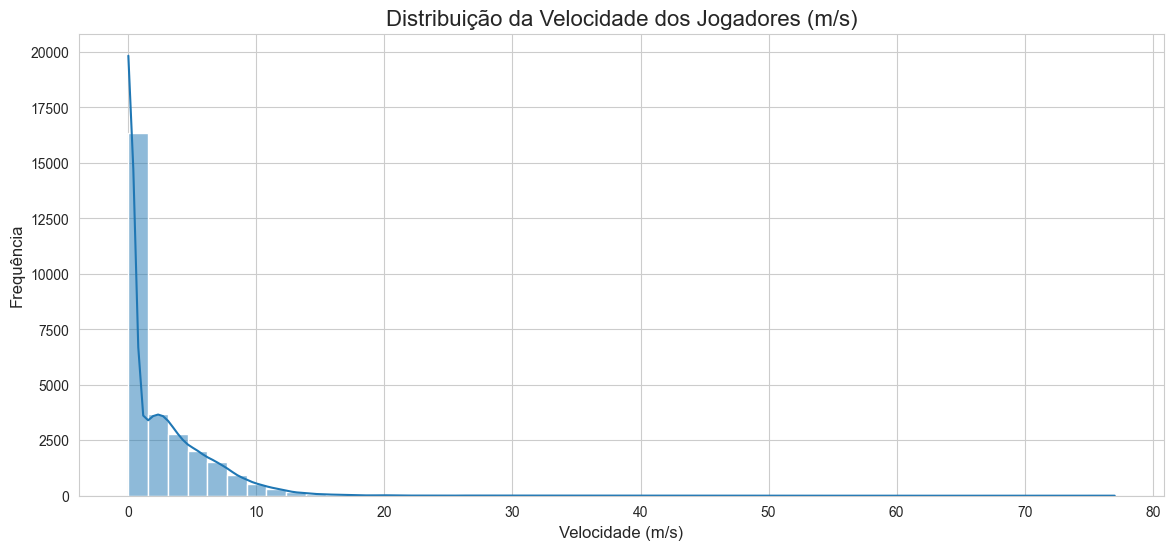


--- Top 5 Momentos de Maior Velocidade ---


,frame_id,shirt,team,speed
1783,20923,9,away,77.031163
3126,28040,17,away,71.913628
3069,20923,17,away,66.719197
5922,27015,47,away,64.049429
122,25579,2,away,60.269613


In [22]:
if not df_jogo.empty:
    # Histograma da velocidade
    plt.figure(figsize=(14, 6))
    sns.histplot(df_jogo['speed'].dropna(), kde=True, bins=50)
    plt.title('Distribuição da Velocidade dos Jogadores (m/s)', fontsize=16)
    plt.xlabel('Velocidade (m/s)', fontsize=12)
    plt.ylabel('Frequência', fontsize=12)
    plt.show()

    # Top 5 momentos de maior velocidade no jogo
    print("\n--- Top 5 Momentos de Maior Velocidade ---")
    top_5_velocidade = df_jogo.sort_values(by='speed', ascending=False).head(5)
    display(top_5_velocidade[['frame_id', 'shirt', 'team', 'speed']])

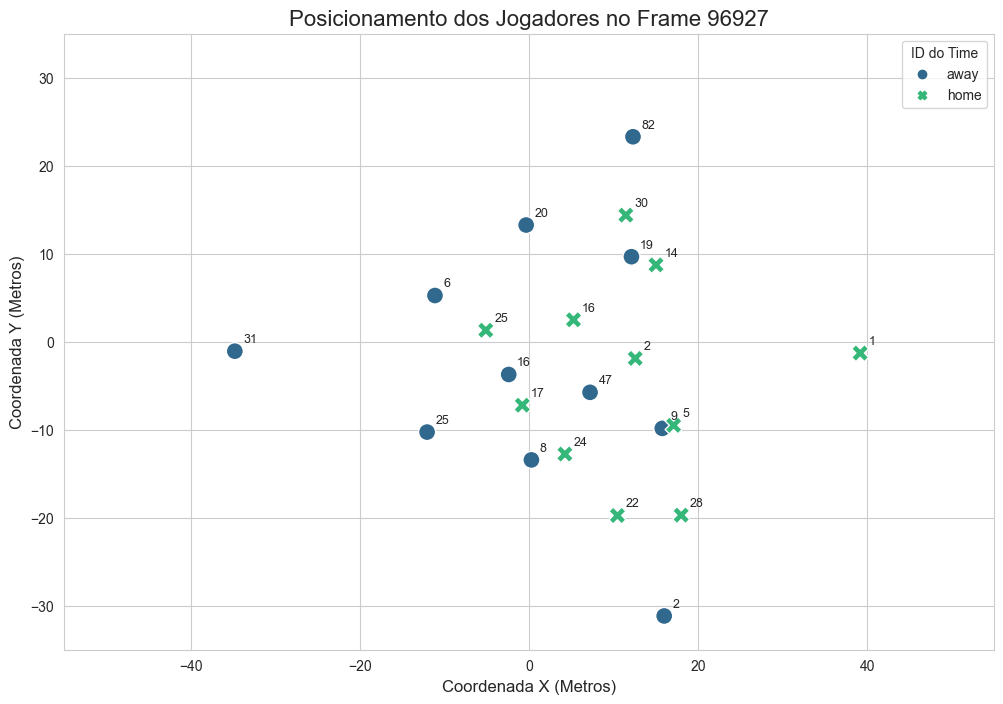

In [23]:
if not df_jogo.empty:
    # Pega um frame_id aleatório do meio do jogo para ter uma boa amostra
    frame_ids_disponiveis = df_jogo['frame_id'].unique()
    frame_exemplo = frame_ids_disponiveis[len(frame_ids_disponiveis) // 2]

    df_frame = df_jogo[df_jogo['frame_id'] == frame_exemplo]

    # Plot
    plt.figure(figsize=(12, 8))
    sns.scatterplot(data=df_frame, x='x', y='y', hue='team', s=150, style='team', palette='viridis')
    
    # Adiciona o ID do jogador ao lado de cada ponto
    for i, row in df_frame.iterrows():
        plt.text(row['x'] + 1, row['y'] + 1, row['shirt'], fontsize=9)

    plt.title(f'Posicionamento dos Jogadores no Frame {frame_exemplo}', fontsize=16)
    plt.xlabel('Coordenada X (Metros)', fontsize=12)
    plt.ylabel('Coordenada Y (Metros)', fontsize=12)
    plt.legend(title='ID do Time')
    plt.grid(True)
    
    # Limites do campo (aproximados, ajuste se necessário)
    plt.xlim(-55, 55)
    plt.ylim(-35, 35)
    
    plt.show()